# 4. A landscape from an equation

**Question:** How do a raster, contour map, and 3D surface represent the same field?
**Objectives:** build a regular grid, preserve row/column orientation, calculate finite-difference
slopes, and distinguish resolution from accuracy. **Time:** 40 minutes.

All elevations are simulated. x and y are local metres, elevation is metres above an arbitrary
datum. There is no Earth CRS. The smooth surface is an analytic teaching model, not a DEM.
[Open in Lab](https://jltobias.github.io/JupyterLite-R/lite/lab/index.html?path=04-terrain-and-rasters.ipynb)

    min_m     max_m spacing_m 
 100.1694  952.4394  100.0000 


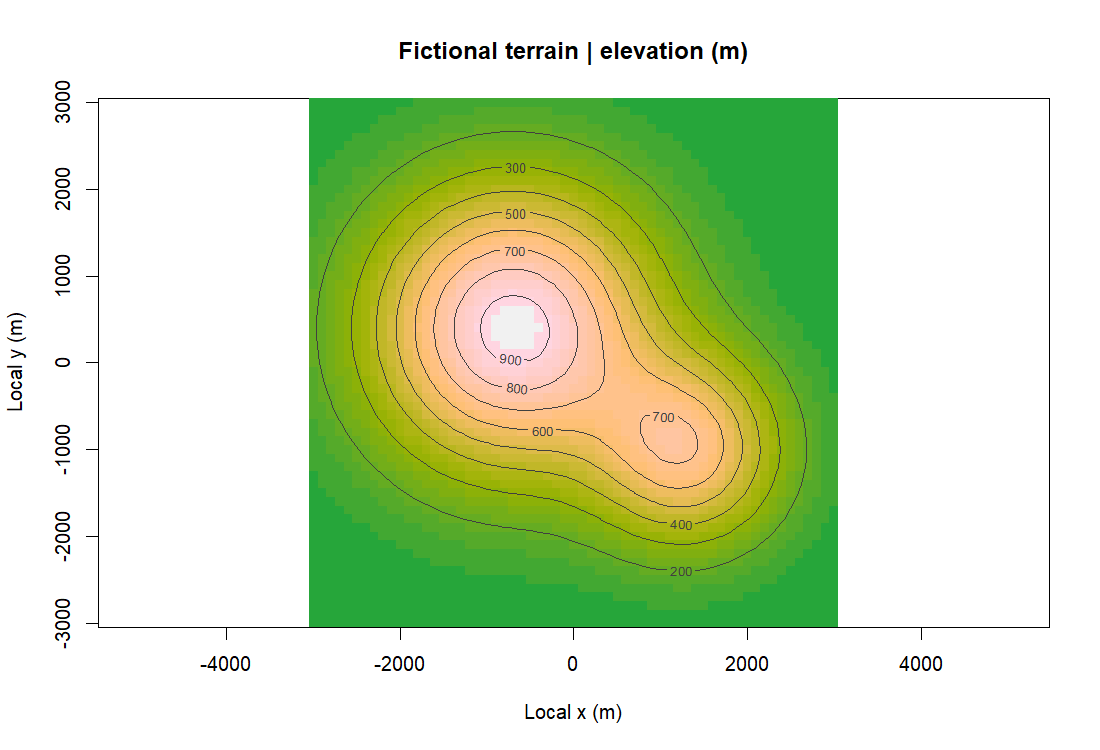

In [1]:
# Project: JupyterLite-R | Chapter 04 | Original analytic terrain.
# Author: project contributors with Codex | Contact: repository Issues.
# Created/updated: 2026-11-16 | Inputs: equation | Outputs: raster, contours, 3D surface.
# Dependencies: base R; optional terra. Change log: initial lesson.
x <- seq(-3000, 3000, length.out = 61)
y <- seq(-3000, 3000, length.out = 61)
#' Evaluate fictional elevations at coordinate pairs in metres; returns metres.
terrain <- function(x, y) {
  100 + 850 * exp(-((x + 700)^2 + (y - 400)^2) / 2400000) +
    550 * exp(-((x - 1300)^2 + (y + 1000)^2) / 1100000)
}
z <- outer(x, y, terrain) # Rows are x; columns are y, as required by image() and persp().
stopifnot(identical(dim(z), c(61L, 61L)), all(is.finite(z)), min(z) > 0)
image(x, y, z, col = hcl.colors(30, "Terrain"), asp = 1,
      xlab = "Local x (m)", ylab = "Local y (m)", main = "Fictional terrain | elevation (m)")
contour(x, y, z, add = TRUE, col = "grey25", labcex = .65)
print(c(min_m = min(z), max_m = max(z), spacing_m = diff(x)[1]))

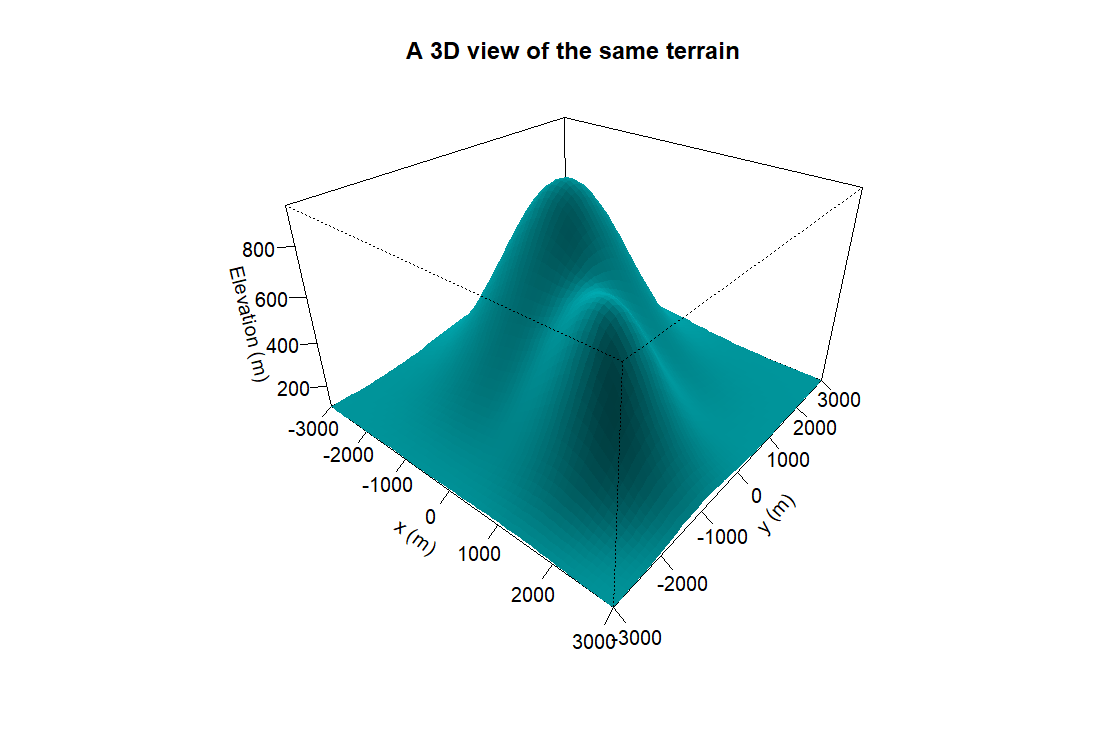

In [2]:
persp(x, y, z, theta = 40, phi = 30, expand = .6, col = "turquoise3", border = NA,
      shade = .4, ticktype = "detailed", xlab = "x (m)", ylab = "y (m)", zlab = "Elevation (m)",
      main = "A 3D view of the same terrain")

## Slope needs horizontal and vertical units
Central differences estimate derivatives at interior cells. Slope is `atan(sqrt(dx^2+dy^2))`,
reported in degrees. Edges are excluded explicitly; they are not silently padded with zeros.
Perspective and `expand` alter appearance; compute slope from the original metric grid.

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
 0.05994  5.92455 13.52127 13.35935 20.92403 26.38983 


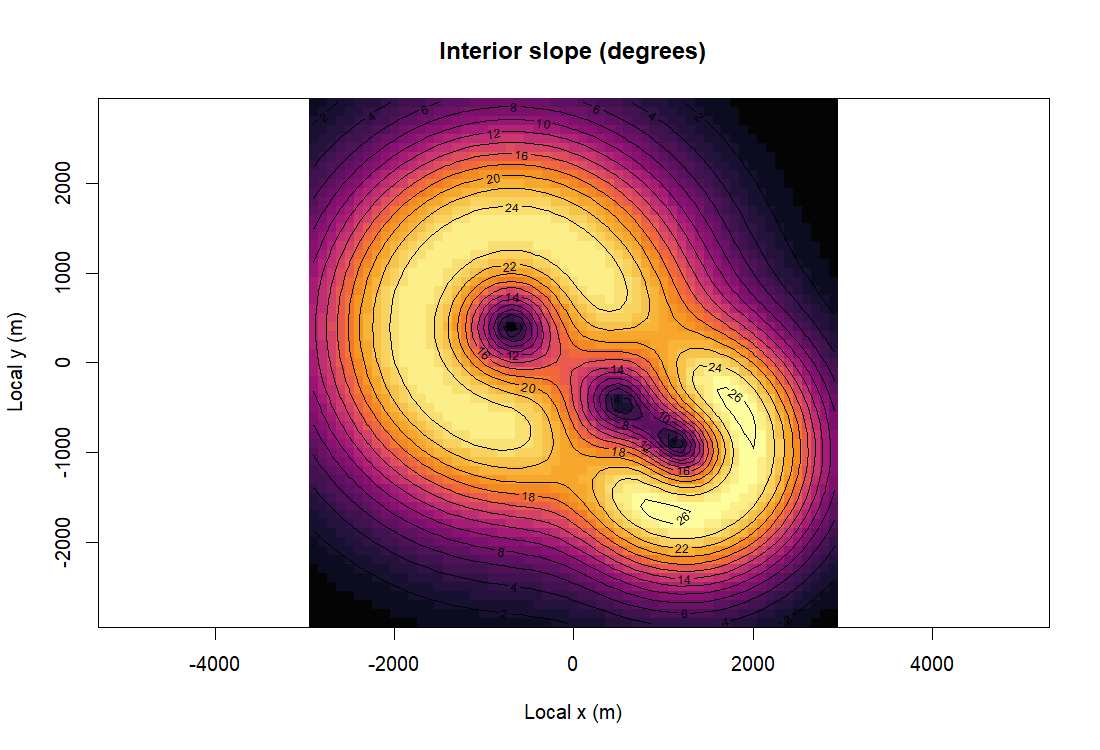

In [3]:
dz_dx <- (z[3:61, 2:60] - z[1:59, 2:60]) / (2 * diff(x)[1])
dz_dy <- (z[2:60, 3:61] - z[2:60, 1:59]) / (2 * diff(y)[1])
slope <- atan(sqrt(dz_dx^2 + dz_dy^2)) * 180 / pi
stopifnot(all(slope >= 0 & slope < 90))
image(x[2:60], y[2:60], slope, col = hcl.colors(30, "Inferno"), asp = 1,
      xlab = "Local x (m)", ylab = "Local y (m)", main = "Interior slope (degrees)")
contour(x[2:60], y[2:60], slope, add = TRUE)
print(summary(as.vector(slope)))

In [ ]:
if (grepl("emscripten", R.version$platform, fixed = TRUE)) {
  message("Desktop extension: terra failed in the pinned webR 0.5.1 runtime. Run this extension in desktop R; the base raster lesson works in Lab.")
} else if (requireNamespace("terra", quietly = TRUE)) {
  # XYZ input avoids the north-to-south row ordering trap in raw raster assignment.
  xyz <- expand.grid(x = x, y = y)
  xyz$elevation <- as.vector(z)
  raster <- terra::rast(xyz, type = "xyz", crs = "")
  stopifnot(terra::ncell(raster) == length(z))
  reconstructed <- terra::extract(raster, as.matrix(xyz[c("x", "y")]))[, 1]
  stopifnot(max(abs(reconstructed - xyz$elevation)) < 1e-8)
  print(raster)
} else message("Optional desktop terra check skipped: install terra in desktop R to run it.")

## Practice and check
1. Use 31 instead of 61 grid coordinates and generalize the interior index expressions.
2. Turn the terrain into a flat plane; every interior slope should become zero.
3. Change the camera angle. Explain why this changes no elevation.
**Checkpoint:** 3,721 elevations, 100-metre spacing, and a 59 by 59 interior slope grid.
A finer grid samples the equation more densely; it does not make measured terrain more accurate.

## Sources
[R persp](https://stat.ethz.ch/R-manual/R-devel/library/graphics/html/persp.html);
[terra raster constructors](https://rspatial.github.io/terra/reference/rast.html).
This chapter's terrain equation and all elevations are original.